<a href="https://colab.research.google.com/github/katt-05/dl/blob/main/chapter04_classification_and_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is a companion notebook for the book [Deep Learning with Python, Third Edition](https://www.manning.com/books/deep-learning-with-python-third-edition). For readability, it only contains runnable code blocks and section titles, and omits everything else in the book: text paragraphs, figures, and pseudocode.

**If you want to be able to follow what's going on, I recommend reading the notebook side by side with your copy of the book.**

The book's contents are available online at [deeplearningwithpython.io](https://deeplearningwithpython.io).

In [ ]:
!pip install keras keras-hub --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 54.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 78.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 kB 26.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.32.0 which is incompatible.


In [ ]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [ ]:
# @title
import os
from IPython.core.magic import register_cell_magic #백엔드 명령어 실행 가능

@register_cell_magic ##백엔드 명령어 실행 가능
def backend(line, cell): # line=요구하는 백엔드 이름 #cell=코드 내용 문자열 전달
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(
            f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to "
            f"\"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook."
        )

## Classification and regression

### Classifying movie reviews: A binary classification example

#### The IMDb dataset

In [ ]:
from keras.datasets import imdb

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(
    num_words=10000
) #머신러닝 모델 학습용/평가용으로 나누어 할당

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
train_data[0]

[1,
 14,
 22,
 16,
 43,
 530,
 973,
 1622,
 1385,
 65,
 458,
 4468,
 66,
 3941,
 4,
 173,
 36,
 256,
 5,
 25,
 100,
 43,
 838,
 112,
 50,
 670,
 2,
 9,
 35,
 480,
 284,
 5,
 150,
 4,
 172,
 112,
 167,
 2,
 336,
 385,
 39,
 4,
 172,
 4536,
 1111,
 17,
 546,
 38,
 13,
 447,
 4,
 192,
 50,
 16,
 6,
 147,
 2025,
 19,
 14,
 22,
 4,
 1920,
 4613,
 469,
 4,
 22,
 71,
 87,
 12,
 16,
 43,
 530,
 38,
 76,
 15,
 13,
 1247,
 4,
 22,
 17,
 515,
 17,
 12,
 16,
 626,
 18,
 2,
 5,
 62,
 386,
 12,
 8,
 316,
 8,
 106,
 5,
 4,
 2223,
 5244,
 16,
 480,
 66,
 3785,
 33,
 4,
 130,
 12,
 16,
 38,
 619,
 5,
 25,
 124,
 51,
 36,
 135,
 48,
 25,
 1415,
 33,
 6,
 22,
 12,
 215,
 28,
 77,
 52,
 5,
 14,
 407,
 16,
 82,
 2,
 8,
 4,
 107,
 117,
 5952,
 15,
 256,
 4,
 2,
 7,
 3766,
 5,
 723,
 36,
 71,
 43,
 530,
 476,
 26,
 400,
 317,
 46,
 7,
 4,
 2,
 1029,
 13,
 104,
 88,
 4,
 381,
 15,
 297,
 98,
 32,
 2071,
 56,
 26,
 141,
 6,
 194,
 7486,
 18,
 4,
 226,
 22,
 21,
 134,
 476,
 26,
 480,
 5,
 144,
 30,
 5535,
 18,

In [ ]:
train_labels[0] #각 리뷰가 긍정0인지 부정1인지 나타내는 레이블

np.int64(1)

In [ ]:
max([max(sequence) for sequence in train_data]) #시퀀스 순회 후 최댓값 찾아냄
#num word=10000으로 설정했기 때문에 가장 큰 인덱스 9999 출력
#시퀀스: 단어나 데이터가 순서대로 냐열된 형태

9999

In [ ]:
min([min(sequence) for sequence in train_data]) #min number of the sequence

1

In [ ]:
word_index = imdb.get_word_index()
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])
decoded_review = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in train_data[0]]
) #word to integer mapping

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
len(train_data[0])

218

In [ ]:
len(train_data[1])

189

In [ ]:
decoded_review[:100] #traindata[0]앞부분 텍스트

"? this film was just brilliant casting location scenery story direction everyone's really suited the"

#### Preparing the data

In [ ]:
import numpy as np
#데이터전처리
def multi_hot_encode(sequences, num_classes):
    results = np.zeros((len(sequences), num_classes)) #전체 리뷰 개수 10000크기 0행렬
    for i, sequence in enumerate(sequences):
      #전체 훈련/테스트 데이터에서 시퀀스 하나씩 순회하며 인덱스(i)와 내용(sequence)가져옴
        results[i][sequence] = 1.0
        #단어의 인덱스 번호에 해당하는 위치 값 1.0으로 대체
    return results

x_train = multi_hot_encode(train_data, num_classes=10000)
x_test = multi_hot_encode(test_data, num_classes=10000)

In [ ]:
x_train[0]

array([0., 1., 1., ..., 0., 0., 0.])

In [ ]:
y_train = train_labels.astype("float32") #change label
y_test = test_labels.astype("float32")
#정수형 레이블을 실수형으로 바꿈

#### Building your model

In [ ]:
import keras
from keras import layers

model = keras.Sequential(
    [
        layers.Dense(16, activation="relu"), #출력 누련 16게 완전연결층
        layers.Dense(16, activation="relu"), #위와동일
        layers.Dense(1, activation="sigmoid"), #출력을 0-1 확률값을 압축해주는 시그모이드 함수 사용
    ]
)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
#logistic practice
import keras
from keras import layers

model = keras.Sequential(
    [
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ]
)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
history = model.fit(
   x_train,
   y_train,
    epochs=20,
    batch_size=512,
    validation_split=0.2,#전체 훈련 데이터 중 0.2 모델학습에 사용x
   #검증데이터(모델 학습 도중 사용=모의고사)로 따로 분류->과대적합 실시간으로 확인 가능
)

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.7951 - loss: 0.5008 - val_accuracy: 0.8780 - val_loss: 0.3462
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9099 - loss: 0.2649 - val_accuracy: 0.8912 - val_loss: 0.2795
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9361 - loss: 0.1902 - val_accuracy: 0.8922 - val_loss: 0.2719
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9506 - loss: 0.1474 - val_accuracy: 0.8928 - val_loss: 0.2862
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9644 - loss: 0.1146 - val_accuracy: 0.8890 - val_loss: 0.3048
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9739 - loss: 0.0900 - val_accuracy: 0.8808 - val_loss: 0.3419
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9818 - loss: 0.0706 - val_accuracy: 0.8796 - val_loss: 0.3673
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9882 - loss: 0.0550 - val_accuracy: 0.8772 - v

*훈련 데이터(test data) : 학습하는 데 사용되는 데이터 = 교과서

*검증데이터(validation data) : 모델 학습 도중에 성능 평가하는 데이터 = 모의고사

*평가데이터(test data) : 학습 끝난 후 평가에 쓰이는 데이터 = 수능

#### Validating your approach

In [ ]:
x_val = x_train[:10000] #전체 훈련 데이터 중 앞에서 10000개 검증으로 지정
partial_x_train = x_train[10000:] #10000번째부터 끝까지 훈련데이터로 지정
y_val = y_train[:10000]
partial_y_train = y_train[10000:]
#전체 데이터를 수동으로 검증 세트-훈련 세틀 나눔

In [ ]:
history = model.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val),
)

#결과
# accuracy: 1.0000 ->훈련 데이터에 대해서는 완벽히 맞힘
#- loss: 0.0011  -> 훈련 데이터에 대한 로스 매우 낮음
#- val_accuracy: 0.8659 -> 학습하지 않고 처음 보는 데이터에 대한 정확도(낮아)
#- val_loss: 0.7547 -> 검증 데이터에서 발생한 로스(학습 진행될수록 높아짐)


Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9984 - loss: 0.0210 - val_accuracy: 0.8740 - val_loss: 0.4586
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9993 - loss: 0.0158 - val_accuracy: 0.8727 - val_loss: 0.4858
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9998 - loss: 0.0121 - val_accuracy: 0.8725 - val_loss: 0.5119
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9999 - loss: 0.0096 - val_accuracy: 0.8703 - val_loss: 0.5327
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9999 - loss: 0.0078 - val_accuracy: 0.8701 - val_loss: 0.5547
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9999 - loss: 0.0064 - val_accuracy: 0.8688 - val_loss: 0.5748
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9999 - loss: 0.0053 - val_accuracy: 0.8684 - val_loss: 0.5930
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9999 - loss: 0.0045 - val_accuracy: 0.8684 - v

In [ ]:
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=512,
    validation_split=0.2,
) #20% of training data as validation data

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9246 - loss: 0.2922 - val_accuracy: 0.9598 - val_loss: 0.1065
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9581 - loss: 0.1286 - val_accuracy: 0.9474 - val_loss: 0.1333
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9737 - loss: 0.0906 - val_accuracy: 0.9382 - val_loss: 0.1551
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9826 - loss: 0.0682 - val_accuracy: 0.9380 - val_loss: 0.1724
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9891 - loss: 0.0495 - val_accuracy: 0.9320 - val_loss: 0.1915
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9934 - loss: 0.0367 - val_accuracy: 0.9292 - val_loss: 0.2163
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9956 - loss: 0.0284 - val_accuracy: 0.9266 - val_loss: 0.2355
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9978 - loss: 0.0209 - val_accuracy: 0.9230 - v

In [ ]:
history_dict = history.history
#모델 학습 시킬 때 에폭마다 기록되는 손실값, 정확도 등의 데이터 딕셔너리 의 속성 저장
history_dict.keys()
#딕셔너리에 저장되 키(딕셔너리) 값 반환

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

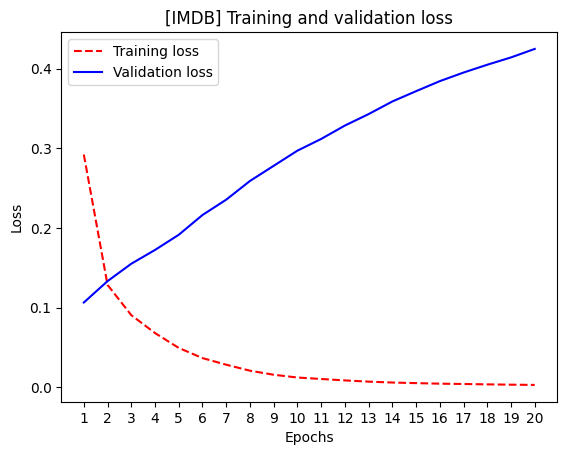

In [ ]:
import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
#에폭 반복 횟수만큼 x 눈금 범위 형성
plt.plot(epochs, loss_values, "r--", label="Training loss") #훈련 손실값
plt.plot(epochs, val_loss_values, "b", label="Validation loss") #검증 손실값
plt.title("[IMDB] Training and validation loss") #
plt.xlabel("Epochs")
plt.xticks(epochs) #눈금번호
plt.ylabel("Loss")
plt.legend()
plt.show()
#검증 로스 증가하는 이유 : 과대적합
#학습을 반복하며 훈련 데이터의 지엽적 패턴까지 과도하게 학습
#-> 새 검증 대이터에는 통하지않음
#검증 로스가 epcoch1 최저 이후 계속 올라감(당연함)->훈련 로스까지 고려해 epoch를 4정도로 조정하는 것이 바람직함

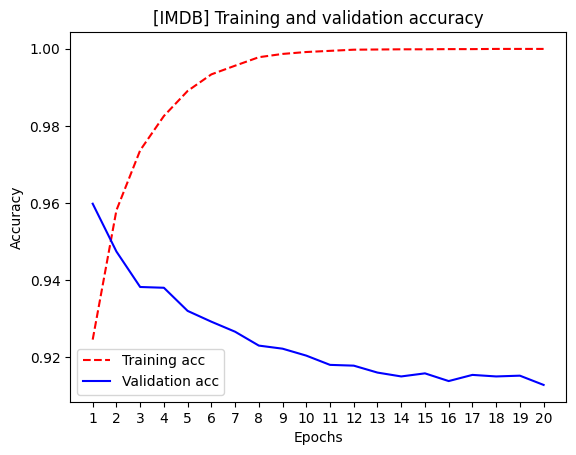

In [ ]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("[IMDB] Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
model = keras.Sequential(
    [
        layers.Dense(16, activation="relu"), #은닉층 #16개의 관점으로 특징 추출
        layers.Dense(16, activation="relu"), #은닉층
        layers.Dense(1, activation="sigmoid"), #출력층 #1개의 관점으로(이진)
    ]
)
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.fit(x_train, y_train, epochs=4, batch_size=512)
results = model.evaluate(x_test, y_test)

Epoch 1/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.7909 - loss: 0.5357
Epoch 2/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9014 - loss: 0.2874
Epoch 3/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9282 - loss: 0.2047
Epoch 4/4
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9426 - loss: 0.1631
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8835 - loss: 0.2973


In [ ]:
results
#[0.2973327040672302, 0.8834799528121948]
#=[loss,accuracy]
#모델이 예측한 결과와 실제 정답 사이 오차가 0.297(손실)
#처음 보는 테스트 데이터 중 모델이 정답 맞힌 비율 88.35(정확)

[0.2973327040672302, 0.8834799528121948]

x train : 학습용 입력데이터

y train : 학습용 정답데이터

x train : 평가용 입력데이터

y train : 평가용 정답데이터

#### Using a trained model to generate predictions on new data

In [ ]:
model.predict(x_test)
#학습이 끝난 모델에 테스트 데이터 입력 후 긍정 부정 최종 예측 확률 계산
#정답 데이터 필요x

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


array([[0.1404747 ],
       [0.9998921 ],
       [0.44131392],
       ...,
       [0.12172904],
       [0.05142864],
       [0.75176334]], dtype=float32)

#### Further experiments

#### Wrapping up

### Classifying newswires: A multiclass classification example

#### The Reuters dataset

In [ ]:
from keras.datasets import reuters

(train_data, train_labels), (test_data, test_labels) = reuters.load_data(
    num_words=10000 #상위 10000개만 남기고 제외
)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
len(train_data)

8982

In [ ]:
len(test_data)

2246

In [ ]:
train_data[10]

[1,
 245,
 273,
 207,
 156,
 53,
 74,
 160,
 26,
 14,
 46,
 296,
 26,
 39,
 74,
 2979,
 3554,
 14,
 46,
 4689,
 4329,
 86,
 61,
 3499,
 4795,
 14,
 61,
 451,
 4329,
 17,
 12]

In [ ]:
# 인덱스(숫자)시퀀스->문장으로 디코딩
word_index = reuters.get_word_index()
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])
decoded_newswire = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in train_data[10]]
)

550378/550378 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


In [ ]:
train_labels[10]

np.int64(3)

#### Preparing the data

In [ ]:
x_train = multi_hot_encode(train_data, num_classes=10000)
x_test = multi_hot_encode(test_data, num_classes=10000)
#단어시퀀스->1000-차원 벡터로

In [ ]:
def one_hot_encode(labels, num_classes=46): #기본 클래스 갯수 46 for (정답 카테고리 종류)
    results = np.zeros((len(labels), num_classes)) #for x
    #전체 리뷰 뉴스 기사 만큼 행*넘클래시스만큼의
    for i, label in enumerate(labels):#각 기사마다 사용된 단어 10000차원 벡터로 변환
        results[i, label] = 1.0
    return results

y_train = one_hot_encode(train_labels) # train_labels=진짜 정답 카테고리 번호
y_test = one_hot_encode(test_labels)

In [ ]:
from keras.utils import to_categorical

y_train = to_categorical(train_labels) #y_train = one_hot_encode(train_labels) 동일
y_test = to_categorical(test_labels)

In [ ]:
y_train[ 5]

array([0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

#### Building your model

In [ ]:
model = keras.Sequential(
    [
        layers.Dense(64, activation="relu"),
        #뉴런 갯수 너무 작으면 과소, 많으면 과대적합
        layers.Dense(64, activation="relu"),
        layers.Dense(46, activation="softmax"), # 46개로 분류되어야함!
    ]
)

In [ ]:
top_3_accuracy = keras.metrics.TopKCategoricalAccuracy(
    k=3, name="top_3_accuracy"
) #46개의 확률값 중 가장 높은 확률 3개 카테고리 후보로 선정
#3개 안에 실제 정답 카텍고리가 들어있으면 성공
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy", top_3_accuracy], # top_3_accuracy 함께 측정
)

#### Validating your approach

In [ ]:
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = y_train[:1000]
partial_y_train = y_train[1000:]

In [ ]:
history = model.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val),
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 213ms/step - accuracy: 0.3717 - loss: 3.2555 - top_3_accuracy: 0.5838 - val_accuracy: 0.5250 - val_loss: 2.4265 - val_top_3_accuracy: 0.7170
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6379 - loss: 1.8731 - top_3_accuracy: 0.7528 - val_accuracy: 0.6610 - val_loss: 1.5645 - val_top_3_accuracy: 0.7780
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7286 - loss: 1.2828 - top_3_accuracy: 0.8196 - val_accuracy: 0.7270 - val_loss: 1.2530 - val_top_3_accuracy: 0.8260
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7828 - loss: 0.9889 - top_3_accuracy: 0.8687 - val_accuracy: 0.7620 - val_loss: 1.1016 - val_top_3_accuracy: 0.8600
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8291 - loss: 0.7835 - top_3_accuracy: 0.9084 - val_accuracy: 0.7820 - val_loss: 1.0198 - val_top_3_accuracy: 0.8780
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8653 - loss: 0.6203 - top_3_a

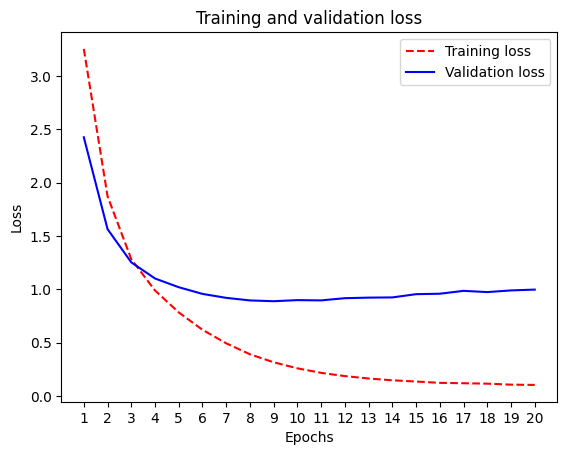

In [ ]:
import matplotlib.pyplot as plt
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, "r--", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

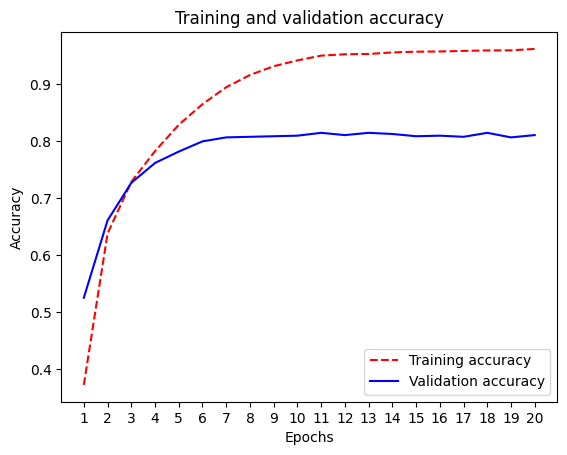

In [ ]:
plt.clf()
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

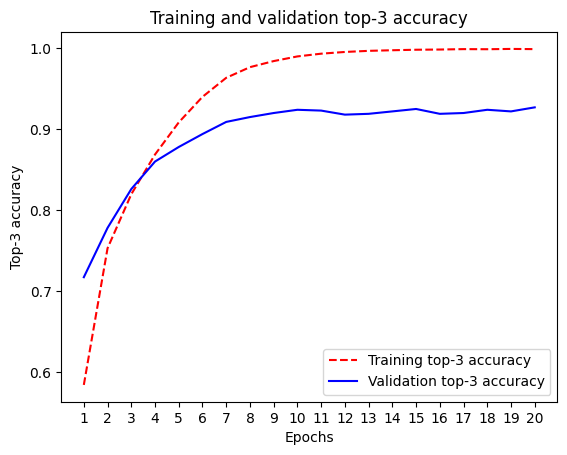

In [ ]:
#상위 3개의 후보 안에만 정답 카테고리가 들어있으면 맞은 것으로
plt.clf()
acc = history.history["top_3_accuracy"]
val_acc = history.history["val_top_3_accuracy"]
plt.plot(epochs, acc, "r--", label="Training top-3 accuracy")
plt.plot(epochs, val_acc, "b", label="Validation top-3 accuracy")
plt.title("Training and validation top-3 accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Top-3 accuracy")
plt.legend()
plt.show()

In [ ]:
model = keras.Sequential(
    [
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(46, activation="softmax"),
    ]
)
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    x_train,
    y_train,
    epochs=9,
    batch_size=512,
)
results = model.evaluate(x_test, y_test)

Epoch 1/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - accuracy: 0.4166 - loss: 3.1500
Epoch 2/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6247 - loss: 1.8778
Epoch 3/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7193 - loss: 1.2922
Epoch 4/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7861 - loss: 0.9913
Epoch 5/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8381 - loss: 0.7708
Epoch 6/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8759 - loss: 0.5949
Epoch 7/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9056 - loss: 0.4586
Epoch 8/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9243 - loss: 0.3605
Epoch 9/9
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9370 - loss: 0.2904
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7907 - loss: 0.9396


In [ ]:
results #[loss,accuracy]
#categorical_crossentropy의 특성때문에 손실값 높음

[0.9395528435707092, 0.790739119052887]

In [ ]:
import copy
test_labels_copy = copy.copy(test_labels)
np.random.shuffle(test_labels_copy) #랜덤하게 셔플
hits_array = np.array(test_labels == test_labels_copy)
#원래 정답, 무작위 가짜정답 비교
#우연히 일치하면 1 틀리면 0
hits_array.mean()
#우연히 일치한 것의 평균비율 계산

np.float64(0.19056099732858414)

#### Generating predictions on new data

In [ ]:
predictions = model.predict(x_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [ ]:
predictions[0].shape

(46,)

In [ ]:
np.sum(predictions[0])

np.float32(0.99999994)

In [ ]:
np.argmax(predictions[0])

np.int64(3)

In [ ]:
y_test[0]

array([0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [ ]:
predict_one[0]

NameError: name 'predict_one' is not defined

#### A different way to handle the labels and the loss

In [ ]:
y_train = train_labels
y_test = test_labels

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

#### The importance of having sufficiently large intermediate layers

In [ ]:
y_train[ 5]

np.int64(4)

In [ ]:
model = keras.Sequential(
    [
        layers.Dense(64, activation="relu"),
        layers.Dense(4, activation="relu"), #중간 은닉층 뉴런 갯수 작음->병목현상
        layers.Dense(46, activation="softmax"),
    ]
)
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
) #64-64-46 과 비교해 정확도 낮아지고 손실값 올라감

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.0549 - loss: 3.4528 - val_accuracy: 0.2410 - val_loss: 2.9856
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4464 - loss: 2.2229 - val_accuracy: 0.6090 - val_loss: 1.6894
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6774 - loss: 1.3380 - val_accuracy: 0.6630 - val_loss: 1.4081
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7179 - loss: 1.1043 - val_accuracy: 0.6780 - val_loss: 1.3421
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7481 - loss: 0.9743 - val_accuracy: 0.7140 - val_loss: 1.3023
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7854 - loss: 0.8784 - val_accuracy: 0.7190 - val_loss: 1.3090
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8063 - loss: 0.7985 - val_accuracy: 0.7150 - val_loss: 1.3174
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8131 - loss: 0.7366 - val_accuracy: 0.7230 - val_loss

#### Further experiments

#### Wrapping up

### Predicting house prices: A regression example

#### The California Housing Price dataset

In [ ]:
from keras.datasets import california_housing

(train_data, train_targets), (test_data, test_targets) = (
    california_housing.load_data(version="small")
)

743530/743530 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
train_data.shape

(480, 8)

In [ ]:
test_data.shape

(120, 8)

In [ ]:
train_targets

array([228400., 132900.,  60000.,  95200., 107000., 122500., 132000.,
       290100., 257800., 390100., 220800., 284900.,  97500., 415300.,
        84200., 185600., 216700., 233100., 127000., 182300.,  92300.,
        90700., 102100., 112500., 350700., 156500., 220700., 147400.,
       216700., 275000., 198200., 119100., 289500., 152500., 125000.,
       104500.,  93800.,  89300., 452600., 128600., 311500.,  90000.,
       218200., 131300.,  67500., 139400., 500001., 182600., 111300.,
       112500., 134700.,  71300., 207400., 331400., 107900.,  87500.,
       342200.,  87100., 314700., 368600., 211600., 338900., 366100.,
       164300.,  91700., 261400., 218500., 155400., 273700.,  81800.,
       138800.,  99700., 156300., 140600., 152700., 108900., 351200.,
       126000., 137500., 196900., 240000., 172800., 254200.,  97500.,
       182700., 162500.,  86100., 226700., 412500., 165900., 327100.,
       162500., 188800., 183800.,  90600., 372000., 275000., 151800.,
       125000., 1291

#### Preparing the data

In [ ]:
mean = train_data.mean(axis=0)
std = train_data.std(axis=0)
x_train = (train_data - mean) / std
x_test = (test_data - mean) / std

In [ ]:
y_train = train_targets / 100000
y_test = test_targets / 100000

#### Building your model

In [ ]:
def get_model():
    model = keras.Sequential(
        [
            layers.Dense(64, activation="relu"),
            layers.Dense(64, activation="relu"),
            layers.Dense(1),
        ]
    )
    model.compile(
        optimizer="adam",
        loss="mean_squared_error",
        metrics=["mean_absolute_error"],
    )
    return model

#### Validating your approach using K-fold validation

In [ ]:
k = 4
num_val_samples = len(x_train) // k #전체 훈련 데이터 4개로 나눠줌
num_epochs = 50 #
all_scores = []
for i in range(k): #매번 검증 세트 위치 돌아가며 변
    print(f"Processing fold #{i + 1}")
    fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_x_train = np.concatenate(
        [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    fold_y_train = np.concatenate(
        [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    model = get_model()
    model.fit(
        fold_x_train,
        fold_y_train,
        epochs=num_epochs,
        batch_size=16,
        verbose=0,
    )
    scores = model.evaluate(fold_x_val, fold_y_val, verbose=0)
    val_loss, val_mae = scores
    all_scores.append(val_mae)

In [ ]:
[round(value, 3) for value in all_scores]

In [ ]:
round(np.mean(all_scores), 3)

In [ ]:
k = 4
num_val_samples = len(x_train) // k
num_epochs = 200
all_mae_histories = []
for i in range(k):
    print(f"Processing fold #{i + 1}")
    fold_x_val = x_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_y_val = y_train[i * num_val_samples : (i + 1) * num_val_samples]
    fold_x_train = np.concatenate(
        [x_train[: i * num_val_samples], x_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    fold_y_train = np.concatenate(
        [y_train[: i * num_val_samples], y_train[(i + 1) * num_val_samples :]],
        axis=0,
    )
    model = get_model()
    history = model.fit(
        fold_x_train,
        fold_y_train,
        validation_data=(fold_x_val, fold_y_val),
        epochs=num_epochs,
        batch_size=16,
        verbose=0,
    )
    mae_history = history.history["val_mean_absolute_error"]
    all_mae_histories.append(mae_history)

In [ ]:
average_mae_history = [
    np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)
]

In [ ]:
epochs = range(1, len(average_mae_history) + 1)
plt.plot(epochs, average_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [ ]:
truncated_mae_history = average_mae_history[10:]
epochs = range(10, len(truncated_mae_history) + 10)
plt.plot(epochs, truncated_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

In [ ]:
model = get_model()
model.fit(x_train, y_train, epochs=130, batch_size=16, verbose=0)
test_mean_squared_error, test_mean_absolute_error = model.evaluate(
    x_test, y_test
)

In [ ]:
round(test_mean_absolute_error, 3)

#### Generating predictions on new data

In [ ]:
predictions = model.predict(x_test)
predictions[0]

#### Wrapping up

1. 은닉층 없이 로지스틱 회귀 적용 :

복잡한 패턴 학습 x-> 정확도 떨어지고 로스 올라감

2. 은닉층 1개 또는 3개로 바꾸기

1 과대적합은 덜 일어나지만 정확도의 한계 올라감

3 과대적합 발생


3. 은닉층 뉴런 갯수 조절

많게 -> val_loss 훨씬 일찍, 높게 폭등함 : 과대적합

적게->병목 현상 발생, 정확도 떨어지고 로스 증가

4. binary_crossentropy 대신 mse(Mean Squared Error) 손실 함수 쓰기

mse는 예측, 회귀용
분류에 맞지 않으므로 정확도 떨어

5. relu 대신 tanh 활성화 함수 쓰기

tanh는 값을 -1에서 1 사이로 압축해 주는 쌍곡선 함수
비선형이므로 결과는 비슷하지만 속도 느려지거나 기울기 소실 가능